# Explainable classification of payment difficulty

**Inteligencia Artificial Explicable — Hands-on Project, Unit 2 (Phase II)**

Group: Thales S. A. Camargo, Jhon Corrales Almendariz, Joel Montes de Oca Martínez

This notebook contains the complete analysis behind the report. It fits and interprets the three mandatory
model families on the same data, folds, and instances:

1. a logical model (`DecisionTreeClassifier`, also read as a rule list),
2. `LogisticRegression`,
3. a generalized additive model (`ExplainableBoostingClassifier`, `interactions=0`).

**Protocol.** The labelled data are split once into an 80 % *development* set and a 20 % *hold-out* set
(stratified, seed 411). Every decision — model comparison, hyperparameters, feature transformation and
classification thresholds — is taken with the same five stratified folds of the development set. The hold-out
set is touched only after all decisions are fixed, to confirm the CV estimates and to provide unseen instances
for local explanations. The model submitted for `test.csv` is finally refit on all labelled rows.

**Running.** Run all cells from top to bottom. Locally the notebook reads `../data/train.csv` and
`../data/test.csv`; in Google Colab it asks you to upload both files. A full run takes about 10 minutes
(most of it is the EBM grid search).

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q "interpret>=0.7"

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    brier_score_loss,
    cohen_kappa_score,
    confusion_matrix,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from interpret.glassbox import ExplainableBoostingClassifier

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

SEED = 411
N_JOBS = 2  # parallel workers; Colab provides two cores
TARGET = "payment_difficulty_next_month"
ID_COLUMN = "row_id"
CATEGORICAL = ["sex", "education", "marital_status", "repayment_assistance_plan"]
MONEY = ["credit_limit", "average_bill_6m", "bill_change_sep_to_apr", "total_payment_6m"]

# One fixed colour per model family, used in every figure.
MODEL_COLORS = {"Decision tree": "#2a78d6", "Logistic regression": "#eb6834", "EBM": "#1baf7a"}
REFERENCE_COLOR = "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 220,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    # Figures are drawn close to their printed width (about 7.5 in for a full page width), so these sizes
    # stay legible in the report.
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

## 1. Data

In [3]:
def find_data_dir() -> Path:
    """Return the folder holding train.csv and test.csv (asks for an upload in Colab)."""
    for candidate in (Path("../data"), Path("data"), Path(".")):
        if (candidate / "train.csv").exists() and (candidate / "test.csv").exists():
            return candidate.resolve()
    if IN_COLAB:
        from google.colab import files

        print("Upload train.csv and test.csv")
        files.upload()
        return Path(".").resolve()
    raise FileNotFoundError("train.csv and test.csv were not found in ../data, data/ or the working directory.")


DATA_DIR = find_data_dir()
REPORT_DIR = DATA_DIR.parent / "report"
FIG_DIR = REPORT_DIR / "figures" if REPORT_DIR.exists() else Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")


train = pd.read_csv(DATA_DIR / "train.csv")
# test.csv is completed by this notebook; drop the appended prediction when re-running.
test = pd.read_csv(DATA_DIR / "test.csv").drop(columns=["predicted_class"], errors="ignore")
for frame in (train, test):
    frame[CATEGORICAL] = frame[CATEGORICAL].astype(str)

X = train.drop(columns=[ID_COLUMN, TARGET])
y = train[TARGET].astype(int)
X_test = test[X.columns]
NUMERIC = [column for column in X.columns if column not in CATEGORICAL]

print(f"Training rows: {len(train):,}; test rows: {len(test):,}; predictors: {X.shape[1]}")
print(f"Missing values in train/test: {int(train.isna().sum().sum())}/{int(test.isna().sum().sum())}")
print(f"Positive rate (payment difficulty): {y.mean():.3f}  ->  majority-class accuracy {1 - y.mean():.3f}")
display(X.describe().T.round(2))

Training rows: 25,000; test rows: 5,000; predictors: 15
Missing values in train/test: 0/0
Positive rate (payment difficulty): 0.212  ->  majority-class accuracy 0.788


,count,mean,std,min,25%,50%,75%,max
credit_limit,25000.0,167740.95,129975.98,10000.0,50000.00,140000.00,240000.00,1000000.0
age,25000.0,35.50,9.24,21.0,28.00,34.00,41.00,79.0
latest_repayment_status,25000.0,-0.02,1.12,-2.0,-1.00,0.00,0.00,8.0
maximum_repayment_delay_6m,25000.0,0.68,1.07,0.0,0.00,0.00,2.00,8.0
delayed_months_6m,25000.0,0.83,1.55,0.0,0.00,0.00,1.00,6.0
average_bill_6m,25000.0,44910.44,63267.26,-56000.0,4700.00,21000.00,57100.00,877300.0
bill_change_sep_to_apr,25000.0,12389.51,44068.85,-403600.0,-3000.00,900.00,19900.00,708300.0
total_payment_6m,25000.0,31635.05,57337.82,0.0,6700.00,14400.00,33700.00,2314200.0
payment_to_bill_ratio_6m,25000.0,0.37,0.59,0.0,0.04,0.09,0.60,5.0
zero_payment_months_6m,25000.0,1.23,1.72,0.0,0.00,0.00,2.00,6.0


**Exploratory view of the target.** The empirical rate of payment difficulty per value of the strongest
behavioural variables already shows non-linear patterns (for example, `latest_repayment_status = -1` has a lower
rate than `-2`, and six zero-payment months more than double the risk of five). The data dictionary warns
against assuming linear effects for these summaries, which motivates the comparison between a linear and an
additive model.

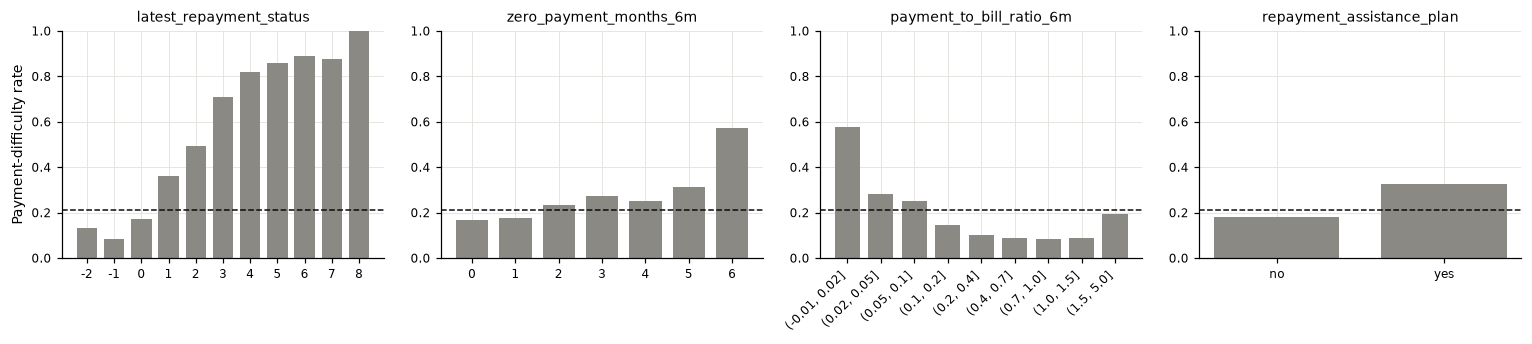

In [4]:
def target_rate(frame: pd.DataFrame, column: str, bins=None) -> pd.DataFrame:
    key = pd.cut(frame[column], bins) if bins is not None else frame[column]
    return frame.groupby(key, observed=True)[TARGET].agg(rows="size", rate="mean")


eda_specs = [
    ("latest_repayment_status", None),
    ("zero_payment_months_6m", None),
    ("payment_to_bill_ratio_6m", [-0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0, 1.5, 5.0]),
    ("repayment_assistance_plan", None),
]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, (column, bins) in zip(axes, eda_specs):
    rates = target_rate(train, column, bins)
    labels = [str(index) for index in rates.index]
    ax.bar(range(len(rates)), rates["rate"], color="#8a8984", width=0.75)
    ax.axhline(y.mean(), color="#0b0b0b", lw=1, ls="--")
    ax.set_xticks(range(len(rates)), labels, rotation=45 if bins else 0, ha="right" if bins else "center", fontsize=8)
    ax.set_title(column, fontsize=9)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Payment-difficulty rate")
fig.tight_layout()
plt.show()

## 2. Validation protocol

In [5]:
X_dev, X_hold, y_dev, y_hold = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(CV.split(X_dev, y_dev))
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)

print(f"Development rows: {len(X_dev):,} (positive rate {y_dev.mean():.3f})")
print(f"Hold-out rows:    {len(X_hold):,} (positive rate {y_hold.mean():.3f})")

Development rows: 20,000 (positive rate 0.212)
Hold-out rows:    5,000 (positive rate 0.212)


## 3. Model specifications and hyperparameter search

* Hyperparameters are selected by **five-fold CV ROC AUC**. AUC measures ranking quality independently of the
  threshold, so it separates the choice of model from the choice of operating point.
* The class imbalance (21 % positives) is handled by **choosing the classification threshold with CV**
  (Section 4) rather than with class weights. Unweighted models keep interpretable, approximately calibrated
  probabilities, and all three families are treated identically.
* For the tree and logistic regression we apply the **one-standard-error rule**: among configurations whose CV
  AUC is within one standard error of the best, we keep the simplest (shallowest tree, strongest regularization).

In [6]:
def simplest_within_one_se(complexity):
    """Return a GridSearchCV refit callable implementing the one-standard-error rule."""

    def select(cv_results):
        mean = np.asarray(cv_results["mean_test_score"])
        standard_error = np.asarray(cv_results["std_test_score"]) / np.sqrt(len(FOLDS))
        best = int(np.argmax(mean))
        eligible = np.flatnonzero(mean >= mean[best] - standard_error[best])
        return int(min(eligible, key=lambda index: complexity(cv_results["params"][index])))

    return select


def grid_search(estimator, grid, refit=True):
    search = GridSearchCV(estimator, grid, scoring="roc_auc", cv=FOLDS, refit=refit, n_jobs=N_JOBS)
    return search.fit(X_dev, y_dev)


def cv_table(search, columns):
    results = pd.DataFrame(search.cv_results_)
    table = results[[f"param_{column}" for column in columns] + ["mean_test_score", "std_test_score"]]
    table.columns = columns + ["cv_auc", "cv_auc_sd"]
    return table.sort_values("cv_auc", ascending=False).round(4)

### 3.1 Logical model: decision tree

Categorical predictors are one-hot encoded; numerical predictors are left on their original scale, because tree
splits are invariant to monotone transformations and raw thresholds are easier to read. We search depth and
minimum leaf size: both directly control the number of rules a reader must follow.

In [7]:
tree_preprocessor = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
tree_pipeline = Pipeline([("prep", tree_preprocessor), ("model", DecisionTreeClassifier(random_state=SEED))])
tree_grid = {"model__max_depth": [2, 3, 4, 5, 6, 7, 8, 10], "model__min_samples_leaf": [25, 50, 100, 200, 400]}
tree_search = grid_search(
    tree_pipeline,
    tree_grid,
    refit=simplest_within_one_se(lambda p: (p["model__max_depth"], -p["model__min_samples_leaf"])),
)
tree_model = tree_search.best_estimator_
tree_params = tree_search.cv_results_["params"][tree_search.best_index_]
print("Selected:", tree_params)
display(cv_table(tree_search, ["model__max_depth", "model__min_samples_leaf"]).head(10))

Selected: {'model__max_depth': 5, 'model__min_samples_leaf': 400}


,model__max_depth,model__min_samples_leaf,cv_auc,cv_auc_sd
15,5,25,0.7553,0.0091
20,6,25,0.7553,0.0099
27,7,100,0.7552,0.0090
24,6,400,0.7549,0.0085
23,6,200,0.7548,0.0076
16,5,50,0.7546,0.0087
22,6,100,0.7544,0.0086
21,6,50,0.7541,0.0083
32,8,100,0.7539,0.0093
17,5,100,0.7534,0.0089


### 3.2 Logistic regression

Numerical predictors are standardized, so coefficients are comparable (change in log-odds per standard
deviation). Categorical predictors use reference (drop-first) coding, which removes the collinearity of full
one-hot encoding. The four monetary variables are heavily right-skewed; whether to apply a signed `log1p`
transform to them is treated as a feature-transformation choice inside the CV grid. `C` controls L2
regularization.

In [8]:
def signed_log1p(values):
    return np.sign(values) * np.log1p(np.abs(values))


logit_preprocessor = ColumnTransformer(
    [
        ("money", Pipeline([("log", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                            ("scale", StandardScaler())]), MONEY),
        ("num", StandardScaler(), [column for column in NUMERIC if column not in MONEY]),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ],
    verbose_feature_names_out=False,
)
logit_pipeline = Pipeline([("prep", logit_preprocessor), ("model", LogisticRegression(max_iter=5000))])
logit_grid = {
    "prep__money__log": ["passthrough", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")],
    "model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10, 100],
}
logit_search = grid_search(logit_pipeline, logit_grid, refit=simplest_within_one_se(lambda p: p["model__C"]))
logit_model = logit_search.best_estimator_
logit_params = logit_search.cv_results_["params"][logit_search.best_index_]
logit_uses_log = logit_params["prep__money__log"] != "passthrough"
print(f"Selected: C={logit_params['model__C']}, signed log1p on monetary variables: {logit_uses_log}")
logit_results = pd.DataFrame(logit_search.cv_results_)
logit_results["log_money"] = logit_results["param_prep__money__log"].astype(str) != "passthrough"
display(logit_results.pivot_table(index="param_model__C", columns="log_money", values="mean_test_score").round(4))

Selected: C=0.01, signed log1p on monetary variables: True


log_money,False,True
param_model__C,,
0.001,0.7427,0.7524
0.003,0.7475,0.7584
0.010,0.7495,0.7614
0.030,0.7499,0.7621
0.100,0.7499,0.7622
0.300,0.7498,0.7621
1.000,0.7497,0.7621
10.000,0.7497,0.7620
100.000,0.7497,0.7620


### 3.3 Explainable Boosting Machine

The EBM receives the raw columns: it bins numerical features itself and treats the string columns as nominal,
giving one shape function per original variable. `interactions=0` keeps the model purely additive. We search
`max_bins` (resolution of the shape functions) and `min_samples_leaf` (smoothness).

In [9]:
ebm_estimator = ExplainableBoostingClassifier(interactions=0, random_state=SEED, n_jobs=N_JOBS)
ebm_grid = {"max_bins": [32, 256, 1024], "min_samples_leaf": [4, 50]}
ebm_search = GridSearchCV(ebm_estimator, ebm_grid, scoring="roc_auc", cv=FOLDS, refit=True, n_jobs=1)
ebm_search.fit(X_dev, y_dev)
ebm_model = ebm_search.best_estimator_
ebm_params = ebm_search.best_params_
print("Selected:", ebm_params)
display(cv_table(ebm_search, ["max_bins", "min_samples_leaf"]))

Selected: {'max_bins': 256, 'min_samples_leaf': 50}


,max_bins,min_samples_leaf,cv_auc,cv_auc_sd
3,256,50,0.7757,0.0089
5,1024,50,0.7756,0.0088
2,256,4,0.7756,0.0090
4,1024,4,0.7753,0.0088
1,32,50,0.7746,0.0083
0,32,4,0.7746,0.0083


### 3.4 Reference models (do not replace the mandatory models)

A majority-class baseline gives the chance level, and an untuned histogram gradient-boosting classifier gives a
black-box reference to measure what, if anything, interpretability costs.

In [10]:
baseline_model = DummyClassifier(strategy="prior").fit(X_dev, y_dev)
blackbox_model = Pipeline([
    ("prep", clone(tree_preprocessor)),
    ("model", HistGradientBoostingClassifier(random_state=SEED)),
]).fit(X_dev, y_dev)

MODELS = {
    "Majority baseline": baseline_model,
    "Decision tree": tree_model,
    "Logistic regression": logit_model,
    "EBM": ebm_model,
    "Gradient boosting (black box)": blackbox_model,
}
GLASSBOX = ["Decision tree", "Logistic regression", "EBM"]

## 4. Cross-validated comparison and threshold choice

Each selected configuration is re-fitted on the same five folds to obtain out-of-fold probabilities. Two
thresholds are chosen on the pooled out-of-fold predictions:

* `t_acc` maximizes accuracy — used for the submitted test predictions, which are graded on accuracy;
* `t_bal` maximizes balanced accuracy — the analysis operating point, which gives equal weight to detecting
  payment difficulty and to avoiding false alarms. It is used for all class-specific results and local cases.

Metrics are then computed fold by fold, so the table reports mean ± standard deviation over the five folds.

In [11]:
def out_of_fold(model):
    probabilities = np.zeros(len(y_dev))
    fold_id = np.zeros(len(y_dev), dtype=int)
    for fold, (fit_index, val_index) in enumerate(FOLDS):
        fitted = clone(model).fit(X_dev.iloc[fit_index], y_dev.iloc[fit_index])
        probabilities[val_index] = fitted.predict_proba(X_dev.iloc[val_index])[:, 1]
        fold_id[val_index] = fold
    return probabilities, fold_id


def best_threshold(target, probabilities, metric):
    scores = [metric(target, (probabilities >= threshold).astype(int)) for threshold in THRESHOLDS]
    return float(THRESHOLDS[int(np.argmax(scores))])


def classification_metrics(target, probabilities, t_acc, t_bal):
    balanced_prediction = (probabilities >= t_bal).astype(int)
    return {
        "auc": roc_auc_score(target, probabilities) if probabilities.std() > 0 else 0.5,
        "brier": brier_score_loss(target, probabilities),
        "accuracy": accuracy_score(target, (probabilities >= t_acc).astype(int)),
        "balanced_accuracy": balanced_accuracy_score(target, balanced_prediction),
        "recall_1": recall_score(target, balanced_prediction, pos_label=1, zero_division=0),
        "recall_0": recall_score(target, balanced_prediction, pos_label=0, zero_division=0),
    }


oof = {}
thresholds = {}
fold_metrics = []
for name, model in MODELS.items():
    probabilities, fold_id = out_of_fold(model)
    oof[name] = probabilities
    if name == "Majority baseline":
        thresholds[name] = {"t_acc": 0.5, "t_bal": 0.5}
    else:
        thresholds[name] = {
            "t_acc": best_threshold(y_dev, probabilities, accuracy_score),
            "t_bal": best_threshold(y_dev, probabilities, balanced_accuracy_score),
        }
    for fold in range(len(FOLDS)):
        mask = fold_id == fold
        row = classification_metrics(y_dev.to_numpy()[mask], probabilities[mask], **thresholds[name])
        fold_metrics.append({"model": name, "fold": fold, **row})

fold_metrics = pd.DataFrame(fold_metrics)
cv_summary = fold_metrics.groupby("model", sort=False).agg(["mean", "std"]).drop(columns="fold")
threshold_columns = pd.DataFrame(thresholds).T
threshold_columns.columns = pd.MultiIndex.from_product([threshold_columns.columns, ["value"]])
cv_summary = cv_summary.join(threshold_columns)
display(cv_summary.round(3))

auc         brier        accuracy        balanced_accuracy        recall_1        recall_0        t_acc t_bal
                                mean    std   mean    std     mean    std              mean    std     mean    std     mean    std value value
model                                                                                                                                         
Majority baseline              0.500  0.000  0.167  0.000    0.788  0.000             0.500  0.000    0.000  0.000    1.000  0.000  0.50  0.50
Decision tree                  0.752  0.011  0.139  0.003    0.812  0.005             0.692  0.009    0.650  0.012    0.735  0.019  0.49  0.18
Logistic regression            0.761  0.008  0.137  0.003    0.814  0.008             0.695  0.009    0.624  0.016    0.767  0.009  0.47  0.22
EBM                            0.776  0.010  0.134  0.003    0.817  0.006             0.705  0.008    0.624  0.011    0.787  0.008  0.49  0.23
Gradient boosting (black box)  0.768  0.012  0.136  0.004    0.815  0.006             0.701  0.013    0.617  0.019    0.785  0.010  0.52  0.23

**Paired comparison.** All models were evaluated on identical folds, so differences can be checked fold by fold.

In [12]:
auc_by_fold = fold_metrics.pivot(index="fold", columns="model", values="auc")
pairs = [("EBM", "Logistic regression"), ("EBM", "Decision tree"), ("Logistic regression", "Decision tree"),
         ("Gradient boosting (black box)", "EBM")]
for first, second in pairs:
    difference = auc_by_fold[first] - auc_by_fold[second]
    print(f"AUC {first} - {second}: mean {difference.mean():+.4f}, sd {difference.std():.4f}, "
          f"positive in {(difference > 0).sum()}/5 folds")

AUC EBM - Logistic regression: mean +0.0143, sd 0.0040, positive in 5/5 folds
AUC EBM - Decision tree: mean +0.0232, sd 0.0066, positive in 5/5 folds
AUC Logistic regression - Decision tree: mean +0.0090, sd 0.0051, positive in 5/5 folds
AUC Gradient boosting (black box) - EBM: mean -0.0074, sd 0.0022, positive in 0/5 folds


**Complexity versus performance.** The tree grid shows how CV AUC changes with depth (best leaf size per depth),
which quantifies the cost of a shorter rule set. The horizontal lines are the other selected models.

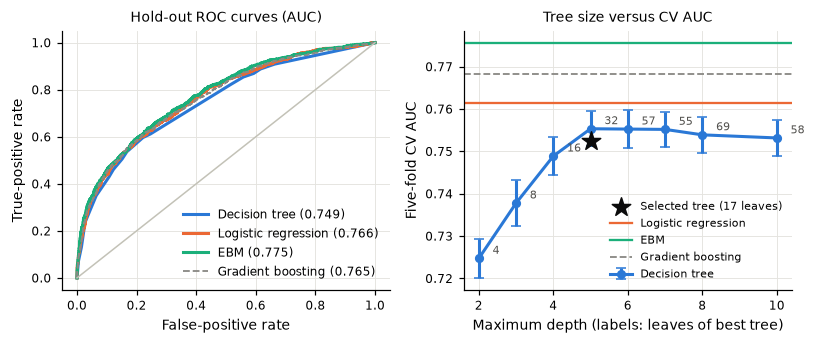

In [13]:
tree_results = pd.DataFrame(tree_search.cv_results_)
by_depth = (tree_results.sort_values("mean_test_score", ascending=False)
            .groupby("param_model__max_depth").head(1).sort_values("param_model__max_depth"))
leaves_by_depth = {
    int(row["param_model__max_depth"]): clone(tree_pipeline).set_params(
        model__max_depth=int(row["param_model__max_depth"]),
        model__min_samples_leaf=int(row["param_model__min_samples_leaf"]),
    ).fit(X_dev, y_dev).named_steps["model"].get_n_leaves()
    for _, row in by_depth.iterrows()
}

fig, (ax_roc, ax_depth) = plt.subplots(1, 2, figsize=(7.5, 3.2))
for name in GLASSBOX + ["Gradient boosting (black box)"]:
    probabilities = MODELS[name].predict_proba(X_hold)[:, 1]
    fpr, tpr, _ = roc_curve(y_hold, probabilities)
    style = dict(color=MODEL_COLORS.get(name, REFERENCE_COLOR), lw=2 if name in GLASSBOX else 1.2,
                 ls="-" if name in GLASSBOX else "--")
    short = "Gradient boosting" if name not in GLASSBOX else name
    ax_roc.plot(fpr, tpr, label=f"{short} ({roc_auc_score(y_hold, probabilities):.3f})", **style)
ax_roc.plot([0, 1], [0, 1], color="#c3c2b7", lw=1)
ax_roc.set(xlabel="False-positive rate", ylabel="True-positive rate", title="Hold-out ROC curves (AUC)")
ax_roc.legend(loc="lower right", frameon=False)

depths = by_depth["param_model__max_depth"].astype(int).to_numpy()
ax_depth.errorbar(depths, by_depth["mean_test_score"], yerr=by_depth["std_test_score"] / np.sqrt(5),
                  color=MODEL_COLORS["Decision tree"], marker="o", ms=5, lw=2, capsize=3, label="Decision tree")
for depth, auc in zip(depths, by_depth["mean_test_score"]):
    ax_depth.annotate(f"{leaves_by_depth[depth]}", (depth, auc), textcoords="offset points", xytext=(9, 3),
                      ha="left", fontsize=7, color="#52514e")
selected_auc = tree_search.cv_results_["mean_test_score"][tree_search.best_index_]
ax_depth.scatter([tree_params["model__max_depth"]], [selected_auc], marker="*", s=160, color="#0b0b0b", zorder=4,
                 label=f"Selected tree ({tree_model.named_steps['model'].get_n_leaves()} leaves)")
for name in ["Logistic regression", "EBM"]:
    ax_depth.axhline(cv_summary.loc[name, ("auc", "mean")], color=MODEL_COLORS[name], lw=1.5, label=name)
ax_depth.axhline(cv_summary.loc["Gradient boosting (black box)", ("auc", "mean")], color=REFERENCE_COLOR,
                 lw=1.2, ls="--", label="Gradient boosting")
ax_depth.set(xlabel="Maximum depth (labels: leaves of best tree)", ylabel="Five-fold CV AUC",
             title="Tree size versus CV AUC")
ax_depth.legend(frameon=False, loc="lower right", fontsize=7)
fig.tight_layout()
save_figure(fig, "performance_overview")
plt.show()

## 5. Hold-out confirmation

Models fitted on the full development set, thresholds fixed from CV. This is the first and only use of the
hold-out labels.

,auc,brier,accuracy,balanced_accuracy,recall_1,recall_0
Majority baseline,0.500,0.167,0.788,0.500,0.000,1.000
Decision tree,0.749,0.138,0.814,0.688,0.597,0.779
Logistic regression,0.766,0.135,0.820,0.690,0.607,0.773
EBM,0.775,0.133,0.825,0.696,0.597,0.795
Gradient boosting (black box),0.765,0.135,0.821,0.691,0.589,0.793


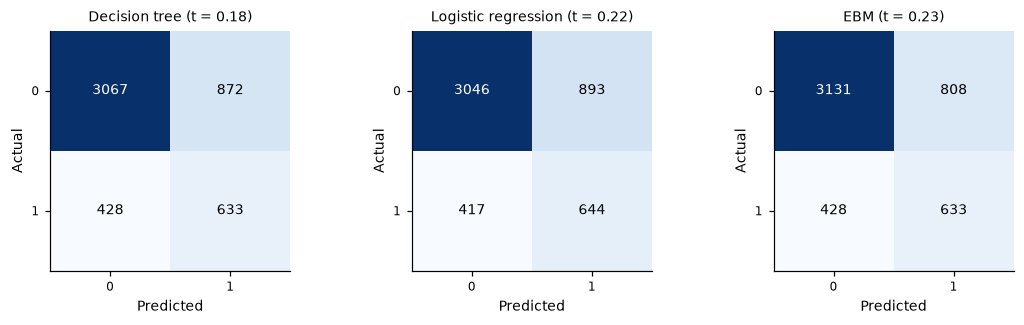

In [14]:
hold_probabilities = {name: model.predict_proba(X_hold)[:, 1] for name, model in MODELS.items()}
hold_summary = pd.DataFrame({
    name: classification_metrics(y_hold.to_numpy(), probabilities, **thresholds[name])
    for name, probabilities in hold_probabilities.items()
}).T
display(hold_summary.round(3))

hold_decisions = {name: (hold_probabilities[name] >= thresholds[name]["t_bal"]).astype(int) for name in GLASSBOX}
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, name in zip(axes, GLASSBOX):
    matrix = confusion_matrix(y_hold, hold_decisions[name])
    ax.imshow(matrix, cmap="Blues")
    for (row, column), value in np.ndenumerate(matrix):
        ax.text(column, row, f"{value}", ha="center", va="center",
                color="white" if value > matrix.max() / 2 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="Predicted", ylabel="Actual",
           title=f"{name} (t = {thresholds[name]['t_bal']:.2f})")
    ax.grid(False)
fig.tight_layout()
plt.show()

**Agreement between the three models** (hold-out decisions at `t_bal`).

In [15]:
agreement = []
for i, first in enumerate(GLASSBOX):
    for second in GLASSBOX[i + 1:]:
        agreement.append({
            "pair": f"{first} vs {second}",
            "agreement": np.mean(hold_decisions[first] == hold_decisions[second]),
            "cohen_kappa": cohen_kappa_score(hold_decisions[first], hold_decisions[second]),
            "probability_correlation": np.corrcoef(hold_probabilities[first], hold_probabilities[second])[0, 1],
        })
agreement = pd.DataFrame(agreement)
all_agree = np.mean((hold_decisions["Decision tree"] == hold_decisions["Logistic regression"])
                    & (hold_decisions["Logistic regression"] == hold_decisions["EBM"]))
display(agreement.round(3))
print(f"All three models agree on {all_agree:.1%} of hold-out instances.")

,pair,agreement,cohen_kappa,probability_correlation
0,Decision tree vs Logistic regression,0.896,0.755,0.894
1,Decision tree vs EBM,0.922,0.812,0.918
2,Logistic regression vs EBM,0.923,0.816,0.955


All three models agree on 87.1% of hold-out instances.


## 6. Global interpretation

Helper functions map encoded columns (e.g. `education_university`) back to the original variable.

In [16]:
def original_feature(encoded_name: str) -> str:
    for column in CATEGORICAL:
        if encoded_name.startswith(column + "_"):
            return column
    return encoded_name


def logit(probability):
    probability = np.clip(probability, 1e-3, 1 - 1e-3)
    return np.log(probability / (1 - probability))

### 6.1 Decision tree: structure and rule list

Tree: depth 5, 17 leaves


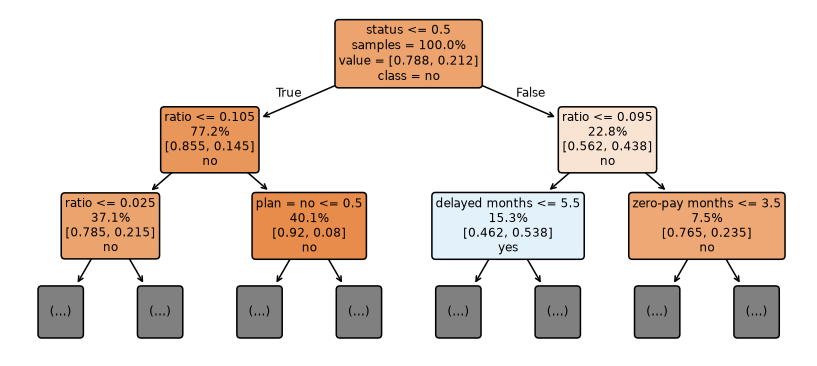

10 of 17 leaves predict difficulty at t_bal = 0.18


,risk,samples,positives_covered,predicts_difficulty,rule
0,0.765,408,312,True,latest_repayment_status ≥ 1 AND payment_to_bill_ratio_6m ≤ 0.095 AND delayed_months_6m ≥ 6 AND bill_change_sep_to_apr ≥ -2949
1,0.645,451,291,True,latest_repayment_status ≥ 1 AND payment_to_bill_ratio_6m ≤ 0.095 AND delayed_months_6m ≥ 6 AND bill_change_sep_to_apr ≤ -2950
2,0.615,631,388,True,latest_repayment_status ≥ 1 AND payment_to_bill_ratio_6m ≤ 0.095 AND delayed_months_6m ≤ 5 AND zero_payment_months_6m ≥ 3
3,0.505,560,283,True,repayment_assistance_plan = yes AND latest_repayment_status ≥ 1 AND payment_to_bill_ratio_6m ≤ 0.095 AND delayed_months_6m ≤ 5 AND zero_payment_months_6m ≤ 2
4,0.426,571,243,True,latest_repayment_status ≤ 0 AND payment_to_bill_ratio_6m ≤ 0.025
5,0.369,1013,374,True,repayment_assistance_plan = no AND latest_repayment_status ≥ 1 AND payment_to_bill_ratio_6m ≤ 0.095 AND delayed_months_6m ≤ 5 AND zero_payment_months_6m ≤ 2
6,0.330,403,133,True,latest_repayment_status ≥ 1 AND payment_to_bill_ratio_6m > 0.095 AND zero_payment_months_6m ≥ 4
7,0.322,687,221,True,latest_repayment_status ≤ 0 AND 0.025 < payment_to_bill_ratio_6m ≤ 0.105 AND age ≤ 24
8,0.281,402,113,True,latest_repayment_status ≥ 1 AND 0.095 < payment_to_bill_ratio_6m ≤ 0.315 AND zero_payment_months_6m ≤ 3
9,0.259,1177,305,True,repayment_assistance_plan = yes AND latest_repayment_status ≤ 0 AND 0.025 < payment_to_bill_ratio_6m ≤ 0.105 AND age ≥ 25


In [17]:
tree_estimator = tree_model.named_steps["model"]
tree_features = list(tree_model.named_steps["prep"].get_feature_names_out())
INTEGER_FEATURES = {column for column in NUMERIC if pd.api.types.is_integer_dtype(X[column])}
print(f"Tree: depth {tree_estimator.get_depth()}, {tree_estimator.get_n_leaves()} leaves")

SHORT_NAMES = {
    "latest_repayment_status": "status",
    "payment_to_bill_ratio_6m": "ratio",
    "delayed_months_6m": "delayed months",
    "zero_payment_months_6m": "zero-pay months",
    "repayment_assistance_plan_no": "plan = no",
    "repayment_assistance_plan_yes": "plan = yes",
}
fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_tree(tree_estimator, feature_names=[SHORT_NAMES.get(name, name) for name in tree_features],
          class_names=["no", "yes"], filled=True, rounded=True, proportion=True, impurity=False, max_depth=2,
          label="root", precision=3, fontsize=8, ax=ax)
fig.tight_layout()
save_figure(fig, "tree_top_levels")
plt.show()


def describe_condition(feature, threshold, goes_left):
    if feature not in X.columns:  # one-hot column "variable_category"
        variable = original_feature(feature)
        category = feature[len(variable) + 1:]
        levels = sorted(X[variable].unique())
        if len(levels) == 2 and goes_left:  # binary variable: "≠ no" reads better as "= yes"
            return (variable, f"{variable} = {[level for level in levels if level != category][0]}")
        return (variable, f"{variable} {'≠' if goes_left else '='} {category}")
    if feature in INTEGER_FEATURES:
        bound = int(np.floor(threshold)) if goes_left else int(np.floor(threshold)) + 1
        return (feature, (feature, "<=" if goes_left else ">=", bound))
    return (feature, (feature, "<=" if goes_left else ">", round(float(threshold), 3)))


def leaf_rules(estimator, features, terminal_nodes=None):
    """Return one row per terminal node (leaves by default) with merged, human-readable conditions."""
    structure = estimator.tree_
    values = structure.value[:, 0, :]
    risk = values[:, 1] / values.sum(axis=1)
    rows = []

    def visit(node, conditions):
        is_leaf = structure.children_left[node] == -1
        if is_leaf or (terminal_nodes is not None and node in terminal_nodes):
            rows.append({"leaf": node, "conditions": conditions, "risk": risk[node],
                         "samples": int(structure.n_node_samples[node])})
            return
        feature = features[structure.feature[node]]
        threshold = structure.threshold[node]
        visit(structure.children_left[node], conditions + [describe_condition(feature, threshold, True)])
        visit(structure.children_right[node], conditions + [describe_condition(feature, threshold, False)])

    visit(0, [])
    for row in rows:
        bounds, texts = {}, []
        for variable, condition in row["conditions"]:
            if isinstance(condition, str):
                texts.append(condition)
                continue
            _, operator, value = condition
            low, high = bounds.get(variable, (None, None))
            if operator == "<=":
                high = value if high is None else min(high, value)
            else:
                lower = value if operator == ">=" else value
                low = (lower, operator) if low is None or lower > low[0] else low
            bounds[variable] = (low, high)
        for variable, (low, high) in bounds.items():
            if low is not None and high is not None:
                texts.append(f"{low[0]} {'≤' if low[1] == '>=' else '<'} {variable} ≤ {high}")
            elif low is not None:
                texts.append(f"{variable} {'≥' if low[1] == '>=' else '>'} {low[0]}")
            else:
                texts.append(f"{variable} ≤ {high}")
        row["rule"] = " AND ".join(texts)
    return pd.DataFrame(rows).drop(columns="conditions")


rules = leaf_rules(tree_estimator, tree_features)
t_bal_tree = thresholds["Decision tree"]["t_bal"]
rules["predicts_difficulty"] = rules["risk"] >= t_bal_tree
dev_leaf = tree_estimator.apply(tree_model.named_steps["prep"].transform(X_dev))
positives_per_leaf = pd.Series(y_dev.to_numpy()).groupby(dev_leaf).sum()
rules["positives_covered"] = rules["leaf"].map(positives_per_leaf).fillna(0).astype(int)
rules = rules.sort_values("risk", ascending=False).reset_index(drop=True)
print(f"{rules['predicts_difficulty'].sum()} of {len(rules)} leaves predict difficulty at t_bal = {t_bal_tree:.2f}")
with pd.option_context("display.max_colwidth", None):
    display(rules[["risk", "samples", "positives_covered", "predicts_difficulty", "rule"]].round(3))

**Rule-set simplification.** At the operating threshold only the predicted class matters, so sibling branches
that end in the same class can be merged without changing a single prediction. We collapse every subtree whose
leaves all predict the same class and read the result as an unordered rule set: *predict difficulty if any
rule fires, otherwise predict no difficulty*. We then check how much of the benefit the riskiest rules alone
keep, adding rules in order of decreasing risk.

In [18]:
structure = tree_estimator.tree_
node_risk = structure.value[:, 0, 1] / structure.value[:, 0, :].sum(axis=1)


def uniform_class(node):
    if structure.children_left[node] == -1:
        return int(node_risk[node] >= t_bal_tree)
    left = uniform_class(structure.children_left[node])
    right = uniform_class(structure.children_right[node])
    return left if left is not None and left == right else None


def collapsed_terminals(node=0):
    if uniform_class(node) is not None:
        return [node]
    return collapsed_terminals(structure.children_left[node]) + collapsed_terminals(structure.children_right[node])


terminals = collapsed_terminals()
simplified = leaf_rules(tree_estimator, tree_features, terminal_nodes=set(terminals))
simplified["predicts_difficulty"] = [bool(uniform_class(node)) for node in simplified["leaf"]]
dev_path = tree_estimator.decision_path(tree_model.named_steps["prep"].transform(X_dev))
simplified["positives_covered"] = [int(y_dev.to_numpy()[dev_path[:, node].toarray().ravel() == 1].sum())
                                   for node in simplified["leaf"]]
simplified = simplified.sort_values("risk", ascending=False).reset_index(drop=True)
print(f"{len(rules)} leaves collapse into {len(simplified)} rules, "
      f"{int(simplified['predicts_difficulty'].sum())} of which predict difficulty.")
with pd.option_context("display.max_colwidth", None):
    display(simplified[["risk", "samples", "positives_covered", "predicts_difficulty", "rule"]].round(3))

positive_rules = simplified[simplified["predicts_difficulty"]]
coverage = []
for k in range(1, len(positive_rules) + 1):
    fired = (np.asarray(dev_path[:, positive_rules["leaf"].iloc[:k].to_numpy()].sum(axis=1)).ravel() > 0).astype(int)
    coverage.append({"rules": k, "balanced_accuracy": balanced_accuracy_score(y_dev, fired),
                     "recall_1": recall_score(y_dev, fired), "flagged_share": fired.mean()})
coverage = pd.DataFrame(coverage)
display(coverage.round(3))

17 leaves collapse into 9 rules, 6 of which predict difficulty.


,risk,samples,positives_covered,predicts_difficulty,rule
0,0.538,3063,1648,True,latest_repayment_status ≥ 1 AND payment_to_bill_ratio_6m ≤ 0.095
1,0.426,571,243,True,latest_repayment_status ≤ 0 AND payment_to_bill_ratio_6m ≤ 0.025
2,0.330,403,133,True,latest_repayment_status ≥ 1 AND payment_to_bill_ratio_6m > 0.095 AND zero_payment_months_6m ≥ 4
3,0.322,687,221,True,latest_repayment_status ≤ 0 AND 0.025 < payment_to_bill_ratio_6m ≤ 0.105 AND age ≤ 24
4,0.281,402,113,True,latest_repayment_status ≥ 1 AND 0.095 < payment_to_bill_ratio_6m ≤ 0.315 AND zero_payment_months_6m ≤ 3
5,0.259,1177,305,True,repayment_assistance_plan = yes AND latest_repayment_status ≤ 0 AND 0.025 < payment_to_bill_ratio_6m ≤ 0.105 AND age ≥ 25
6,0.166,4979,827,False,repayment_assistance_plan = no AND latest_repayment_status ≤ 0 AND 0.025 < payment_to_bill_ratio_6m ≤ 0.105 AND age ≥ 25
7,0.154,700,108,False,latest_repayment_status ≥ 1 AND payment_to_bill_ratio_6m > 0.315 AND zero_payment_months_6m ≤ 3
8,0.080,8018,644,False,latest_repayment_status ≤ 0 AND payment_to_bill_ratio_6m > 0.105


,rules,balanced_accuracy,recall_1,flagged_share
0,1,0.649,0.388,0.153
1,2,0.668,0.446,0.182
2,3,0.675,0.477,0.202
3,4,0.686,0.529,0.236
4,5,0.690,0.556,0.256
5,6,0.698,0.628,0.315


In [19]:
tree_importance = (pd.Series(tree_estimator.feature_importances_, index=tree_features)
                   .groupby(original_feature).sum().sort_values(ascending=False))
display(tree_importance.round(3).to_frame("impurity_importance"))

,impurity_importance
latest_repayment_status,0.514
payment_to_bill_ratio_6m,0.336
delayed_months_6m,0.054
zero_payment_months_6m,0.038
repayment_assistance_plan,0.030
age,0.022
bill_change_sep_to_apr,0.005
education,0.000
credit_limit,0.000
average_bill_6m,0.000


### 6.2 Logistic regression: standardized coefficients and their stability across folds

In [20]:
logit_features = list(logit_model.named_steps["prep"].get_feature_names_out())
coefficients = pd.Series(logit_model.named_steps["model"].coef_[0], index=logit_features)
fold_coefficients = pd.DataFrame(
    [clone(logit_model).fit(X_dev.iloc[fit], y_dev.iloc[fit]).named_steps["model"].coef_[0] for fit, _ in FOLDS],
    columns=logit_features,
)
coefficient_table = pd.DataFrame({
    "coefficient": coefficients,
    "odds_ratio": np.exp(coefficients),
    "fold_min": fold_coefficients.min(),
    "fold_max": fold_coefficients.max(),
}).sort_values("coefficient")
print(f"Intercept (log-odds for a reference-category client with average numeric values): "
      f"{logit_model.named_steps['model'].intercept_[0]:.3f}")
display(coefficient_table.round(3))

Intercept (log-odds for a reference-category client with average numeric values): -1.629


,coefficient,odds_ratio,fold_min,fold_max
total_payment_6m,-0.507,0.602,-0.520,-0.462
age,-0.095,0.909,-0.107,-0.079
maximum_repayment_delay_6m,-0.076,0.926,-0.078,-0.046
sex_male,-0.073,0.930,-0.091,-0.048
marital_status_other_or_unknown,-0.053,0.948,-0.081,-0.011
education_university,-0.052,0.950,-0.082,-0.025
education_other,-0.008,0.992,-0.034,0.012
education_unknown,0.006,1.006,-0.020,0.027
bill_change_sep_to_apr,0.030,1.030,0.025,0.039
average_bill_6m,0.049,1.050,0.030,0.056


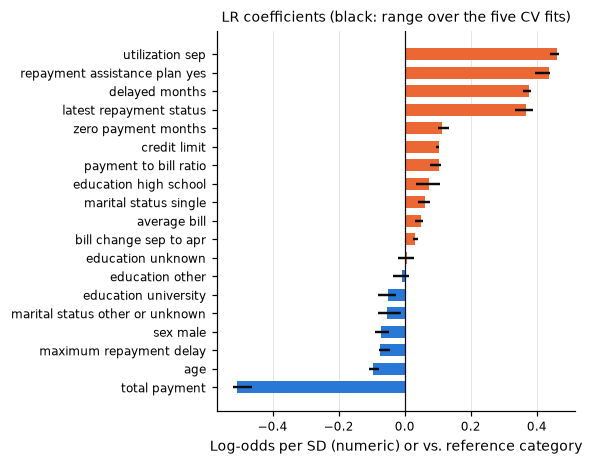

In [21]:
def pretty(name):
    return name.replace("_6m", "").replace("_", " ")


fig, ax = plt.subplots(figsize=(5.4, 4.3))
ordered = coefficient_table
positions = np.arange(len(ordered))
colors = np.where(ordered["coefficient"] > 0, "#eb6834", "#2a78d6")
ax.barh(positions, ordered["coefficient"], color=colors, height=0.65)
ax.hlines(positions, ordered["fold_min"], ordered["fold_max"], color="#0b0b0b", lw=1.6)
ax.set_yticks(positions, [pretty(name) for name in ordered.index])
ax.axvline(0, color="#0b0b0b", lw=0.8)
ax.set_xlabel("Log-odds per SD (numeric) or vs. reference category")
ax.set_title("LR coefficients (black: range over the five CV fits)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_figure(fig, "logit_coefficients")
plt.show()

### 6.3 EBM: shape functions

Each panel is the learned contribution (log-odds) of one variable; the band is ± one standard deviation across
the EBM's internal bagged fits. Contributions are centred so their average over the training data is zero.

,mean_absolute_contribution
payment_to_bill_ratio_6m,0.338
latest_repayment_status,0.235
delayed_months_6m,0.183
zero_payment_months_6m,0.174
repayment_assistance_plan,0.173
utilization_sep,0.148
age,0.144
total_payment_6m,0.103
bill_change_sep_to_apr,0.065
maximum_repayment_delay_6m,0.055


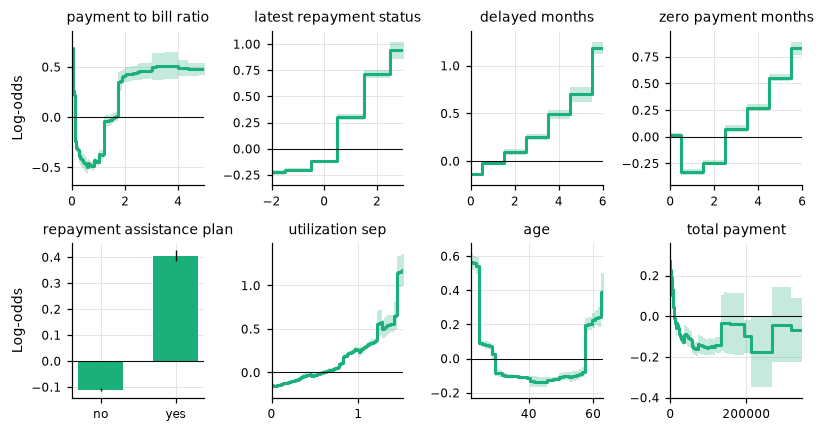

In [22]:
ebm_global = ebm_model.explain_global()
ebm_importance = pd.Series(ebm_model.term_importances(), index=ebm_model.term_names_).sort_values(ascending=False)
display(ebm_importance.round(3).to_frame("mean_absolute_contribution"))


def ebm_shape(term_name):
    data = ebm_global.data(ebm_model.term_names_.index(term_name))
    names, scores = list(data["names"]), np.asarray(data["scores"])
    upper, lower = np.asarray(data["upper_bounds"]), np.asarray(data["lower_bounds"])
    return names, scores, lower, upper


def plot_ebm_term(ax, term_name, color=MODEL_COLORS["EBM"]):
    names, scores, lower, upper = ebm_shape(term_name)
    if term_name in CATEGORICAL:
        positions = np.arange(len(scores))
        ax.bar(positions, scores, color=color, width=0.6)
        ax.errorbar(positions, scores, yerr=[scores - lower, upper - scores], fmt="none", ecolor="#0b0b0b", lw=0.9)
        ax.set_xticks(positions, names)
    else:
        edges = np.asarray(names, dtype=float)
        ax.fill_between(edges, np.r_[lower, lower[-1]], np.r_[upper, upper[-1]], step="post", color=color,
                        alpha=0.25, lw=0)
        ax.step(edges, np.r_[scores, scores[-1]], where="post", color=color, lw=2)
        low, high = X_dev[term_name].quantile([0.005, 0.995])
        ax.set_xlim(low, high)
        visible = (edges[1:] > low) & (edges[:-1] < high)
        span = upper[visible].max() - lower[visible].min()
        ax.set_ylim(lower[visible].min() - 0.08 * span, upper[visible].max() + 0.08 * span)
    ax.axhline(0, color="#0b0b0b", lw=0.7)
    ax.set_title(pretty(term_name))


top_terms = list(ebm_importance.index[:8])
fig, axes = plt.subplots(2, 4, figsize=(7.5, 4.0))
for ax, term in zip(axes.ravel(), top_terms):
    plot_ebm_term(ax, term)
for ax in axes[:, 0]:
    ax.set_ylabel("Log-odds")
fig.tight_layout()
save_figure(fig, "ebm_shapes")
plt.show()

### 6.4 Same variable, three explanations

To compare what the three families learned about a variable, we compute for each model the centred partial
dependence on the log-odds scale: the variable is set to each grid value for 1,000 development rows and the
average log-odds is recorded. For the additive models (logistic regression, EBM) this recovers exactly their
per-variable effect; for the tree it is the average effect of the variable through its splits.

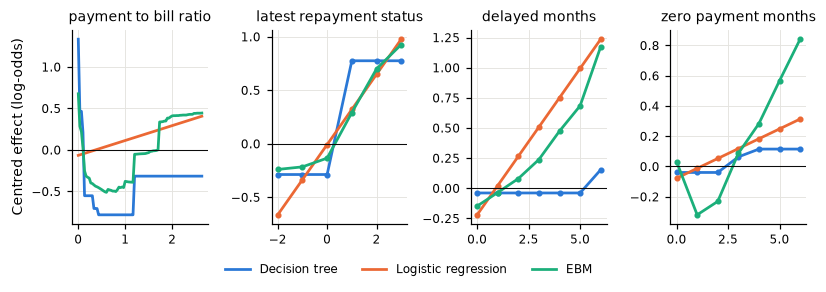

In [23]:
reference_rows = X_dev.sample(1000, random_state=SEED)


def effect_curve(model, feature, grid):
    values = []
    for value in grid:
        modified = reference_rows.copy()
        modified[feature] = value
        values.append(logit(model.predict_proba(modified)[:, 1]).mean())
    values = np.asarray(values)
    baseline = logit(model.predict_proba(reference_rows)[:, 1]).mean()
    return values - baseline


def feature_grid(feature):
    low, high = X_dev[feature].quantile([0.01, 0.99])
    if feature in INTEGER_FEATURES and X_dev[feature].nunique() <= 15:
        return np.arange(int(low), int(high) + 1)
    return np.linspace(low, high, 80)


compare_features = [f for f in ebm_importance.index if f in NUMERIC][:4]
fig, axes = plt.subplots(1, 4, figsize=(7.5, 2.6))
for ax, feature in zip(axes, compare_features):
    grid = feature_grid(feature)
    step = feature in INTEGER_FEATURES and len(grid) <= 15
    for name in GLASSBOX:
        curve = effect_curve(MODELS[name], feature, grid)
        if step:
            ax.plot(grid, curve, color=MODEL_COLORS[name], lw=1.8, marker="o", ms=3, label=name)
        else:
            ax.plot(grid, curve, color=MODEL_COLORS[name], lw=1.8, label=name)
    ax.axhline(0, color="#0b0b0b", lw=0.7)
    ax.set_title(pretty(feature))
axes[0].set_ylabel("Centred effect (log-odds)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(fig, "effect_comparison")
plt.show()

### 6.5 A common yardstick: permutation importance

Native importances are not comparable across families (impurity reduction, coefficient size and mean absolute
EBM contribution measure different things). Permutation importance on the hold-out set measures, for every
model in the same way, how much the AUC drops when one original variable is shuffled.

,Decision tree,Logistic regression,EBM
payment_to_bill_ratio_6m,0.1223,0.0039,0.0315
zero_payment_months_6m,0.0095,0.0062,0.0208
latest_repayment_status,0.0567,0.0306,0.0188
delayed_months_6m,0.0022,0.0343,0.0186
age,0.0071,0.0040,0.0107
utilization_sep,0.0000,0.0560,0.0073
repayment_assistance_plan,0.0065,0.0061,0.0069
total_payment_6m,0.0000,0.0729,0.0039
bill_change_sep_to_apr,0.0002,0.0000,0.0022
maximum_repayment_delay_6m,0.0000,0.0012,0.0018


Spearman rank correlation of permutation importances:


,Decision tree,Logistic regression,EBM
Decision tree,1.00,0.36,0.85
Logistic regression,0.36,1.00,0.73
EBM,0.85,0.73,1.00


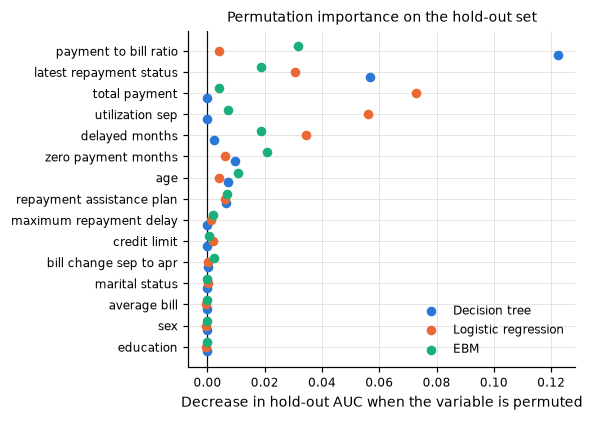

In [24]:
permutation = {}
for name in GLASSBOX:
    result = permutation_importance(MODELS[name], X_hold, y_hold, scoring="roc_auc", n_repeats=10,
                                    random_state=SEED, n_jobs=1)
    permutation[name] = pd.Series(result.importances_mean, index=X_hold.columns)
permutation = pd.DataFrame(permutation)
permutation = permutation.loc[permutation.mean(axis=1).sort_values().index]
display(permutation.sort_values("EBM", ascending=False).round(4))
print("Spearman rank correlation of permutation importances:")
display(permutation.corr(method="spearman").round(2))

fig, ax = plt.subplots(figsize=(5.4, 3.9))
positions = np.arange(len(permutation))
for offset, name in zip((-0.22, 0, 0.22), GLASSBOX):
    ax.scatter(permutation[name], positions + offset, color=MODEL_COLORS[name], s=28, label=name, zorder=3)
ax.set_yticks(positions, [pretty(name) for name in permutation.index])
ax.axvline(0, color="#0b0b0b", lw=0.8)
ax.set_xlabel("Decrease in hold-out AUC when the variable is permuted")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Permutation importance on the hold-out set")
fig.tight_layout()
save_figure(fig, "permutation_importance")
plt.show()

## 7. Local interpretation: the same instances for all three models

Four hold-out instances are selected by fixed rules, using each model's `t_bal` decisions:

* **A** — actual class 0, all three models correct (the most typical such case: EBM probability closest to the
  median of the group);
* **B** — actual class 1, all three models correct (most typical, same criterion);
* **C** — actual class 1 on which the models disagree, chosen as the case with the largest spread in log-odds;
* **D** — actual class 0 on which the models disagree, same criterion.

Every prediction is decomposed into log-odds contributions per original variable: for the EBM the shape-function
values; for logistic regression coefficient × standardized value (relative to the average client and the
reference categories); for the tree the change in leaf log-odds produced by each split on the decision path.

In [25]:
hold_frame = pd.DataFrame({name: hold_probabilities[name] for name in GLASSBOX}, index=X_hold.index)
decision_frame = pd.DataFrame(hold_decisions, index=X_hold.index)
unanimous = decision_frame.nunique(axis=1) == 1
logit_spread = logit(hold_frame).std(axis=1)


def most_typical(mask):
    candidates = hold_frame.loc[mask, "EBM"]
    return (candidates - candidates.median()).abs().idxmin()


actual = y_hold
case_index = {
    "A": most_typical(unanimous & (actual == 0) & (decision_frame["EBM"] == 0)),
    "B": most_typical(unanimous & (actual == 1) & (decision_frame["EBM"] == 1)),
    "C": logit_spread[~unanimous & (actual == 1)].idxmax(),
    "D": logit_spread[~unanimous & (actual == 0)].idxmax(),
}
local_cases = pd.DataFrame({
    "row_id": train.loc[list(case_index.values()), ID_COLUMN].to_numpy(),
    "actual": actual.loc[list(case_index.values())].to_numpy(),
    **{f"p_{name}": hold_frame.loc[list(case_index.values()), name].round(3).to_numpy() for name in GLASSBOX},
    **{f"pred_{name}": decision_frame.loc[list(case_index.values()), name].to_numpy() for name in GLASSBOX},
}, index=list(case_index))
display(local_cases)
with pd.option_context("display.max_columns", None):
    display(X_hold.loc[list(case_index.values())].set_index(local_cases.index).T)

,row_id,actual,p_Decision tree,p_Logistic regression,p_EBM,pred_Decision tree,pred_Logistic regression,pred_EBM
A,CR26-119951,0,0.118,0.134,0.096,0,0,0
B,CR26-109661,1,0.505,0.469,0.533,1,1,1
C,CR26-115142,1,0.154,0.500,0.550,0,1,1
D,CR26-125976,0,0.062,0.387,0.278,0,1,1


,A,B,C,D
credit_limit,100000,110000,20000,30000
sex,female,female,female,female
education,university,university,high_school,high_school
marital_status,single,single,single,married
age,23,25,31,42
latest_repayment_status,0,2,1,0
maximum_repayment_delay_6m,0,2,3,0
delayed_months_6m,0,1,4,0
average_bill_6m,2200,94200,-400,29100
bill_change_sep_to_apr,11300,28700,2000,46000


In [26]:
def tree_contributions(row):
    encoded = tree_model.named_steps["prep"].transform(row)
    path = tree_estimator.decision_path(encoded).indices
    values = tree_estimator.tree_.value[:, 0, :]
    node_logit = logit(values[:, 1] / values.sum(axis=1))
    contributions = pd.Series(0.0, index=X.columns)
    for parent, child in zip(path[:-1], path[1:]):
        contributions[original_feature(tree_features[tree_estimator.tree_.feature[parent]])] += (
            node_logit[child] - node_logit[parent])
    return contributions, node_logit[0]


def logit_contributions(row):
    encoded = logit_model.named_steps["prep"].transform(row)[0]
    terms = pd.Series(encoded * logit_model.named_steps["model"].coef_[0], index=logit_features)
    contributions = terms.groupby(original_feature).sum().reindex(X.columns, fill_value=0.0)
    return contributions, logit_model.named_steps["model"].intercept_[0]


def ebm_contributions(row):
    terms = pd.Series(ebm_model.eval_terms(row)[0], index=ebm_model.term_names_)
    return terms.reindex(X.columns, fill_value=0.0), float(ebm_model.intercept_[0])


CONTRIBUTORS = {"Decision tree": tree_contributions, "Logistic regression": logit_contributions,
                "EBM": ebm_contributions}
local_contributions = {}
for case, index in case_index.items():
    row = X_hold.loc[[index]]
    local_contributions[case] = pd.DataFrame({name: CONTRIBUTORS[name](row)[0] for name in GLASSBOX})
    bases = {name: round(CONTRIBUTORS[name](row)[1], 3) for name in GLASSBOX}
    print(f"Case {case}: base log-odds {bases}")
    display(local_contributions[case].loc[local_contributions[case].abs().max(axis=1)
                                          .sort_values(ascending=False).index[:8]].round(3))

Case A: base log-odds {'Decision tree': np.float64(-1.312), 'Logistic regression': np.float64(-1.629), 'EBM': -1.575}


,Decision tree,Logistic regression,EBM
payment_to_bill_ratio_6m,-0.749,-0.004,-0.416
age,0.632,0.129,0.559
latest_repayment_status,-0.461,0.006,-0.119
utilization_sep,0.000,-0.342,-0.131
zero_payment_months_6m,0.000,-0.016,-0.331
delayed_months_6m,0.000,-0.202,-0.133
total_payment_6m,0.000,0.155,0.109
repayment_assistance_plan,-0.120,0.000,-0.110


Case B: base log-odds {'Decision tree': np.float64(-1.312), 'Logistic regression': np.float64(-1.629), 'EBM': -1.575}


,Decision tree,Logistic regression,EBM
latest_repayment_status,1.064,0.663,0.715
utilization_sep,0.000,0.658,0.256
repayment_assistance_plan,0.354,0.438,0.406
payment_to_bill_ratio_6m,0.401,-0.056,0.235
delayed_months_6m,-0.256,0.040,-0.021
total_payment_6m,0.000,-0.242,-0.117
zero_payment_months_6m,-0.229,-0.081,0.020
age,0.000,0.108,0.093


Case C: base log-odds {'Decision tree': np.float64(-1.312), 'Logistic regression': np.float64(-1.629), 'EBM': -1.575}


,Decision tree,Logistic regression,EBM
payment_to_bill_ratio_6m,-1.249,0.721,0.478
latest_repayment_status,1.064,0.334,0.306
delayed_months_6m,0.000,0.769,0.489
utilization_sep,0.000,-0.479,-0.146
repayment_assistance_plan,0.000,0.438,0.406
average_bill_6m,0.000,-0.278,-0.162
zero_payment_months_6m,-0.204,0.115,0.076
credit_limit,0.000,-0.195,0.015


Case D: base log-odds {'Decision tree': np.float64(-1.312), 'Logistic regression': np.float64(-1.629), 'EBM': -1.575}


,Decision tree,Logistic regression,EBM
utilization_sep,0.000,1.796,1.339
payment_to_bill_ratio_6m,-0.749,-0.029,-0.319
latest_repayment_status,-0.461,0.006,-0.119
total_payment_6m,0.000,-0.271,-0.113
delayed_months_6m,0.000,-0.202,-0.133
bill_change_sep_to_apr,0.000,0.031,0.156
credit_limit,0.000,-0.150,0.019
age,-0.069,-0.067,-0.134


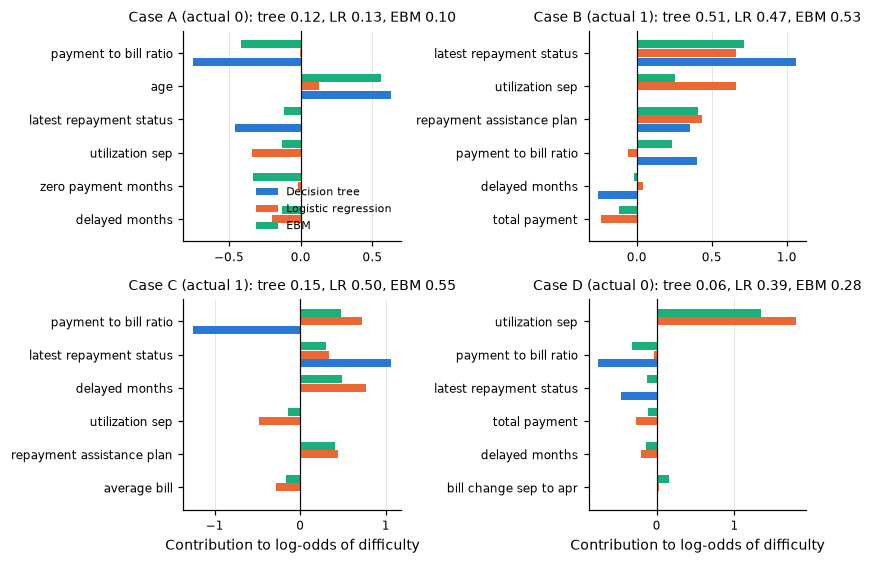

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(7.5, 5.2))
for ax, (case, contributions) in zip(axes.ravel(), local_contributions.items()):
    top = contributions.abs().max(axis=1).sort_values(ascending=False).index[:6][::-1]
    positions = np.arange(len(top))
    for offset, name in zip((-0.26, 0, 0.26), GLASSBOX):
        ax.barh(positions + offset, contributions.loc[top, name], height=0.24, color=MODEL_COLORS[name],
                label=name)
    ax.set_yticks(positions, [pretty(feature) for feature in top])
    ax.axvline(0, color="#0b0b0b", lw=0.8)
    info = local_cases.loc[case]
    probabilities = ", ".join(f"{short} {info[f'p_{name}']:.2f}" for short, name in
                              zip(("tree", "LR", "EBM"), GLASSBOX))
    ax.set_title(f"Case {case} (actual {info['actual']}): {probabilities}")
    ax.grid(axis="y", visible=False)
for ax in axes[1]:
    ax.set_xlabel("Contribution to log-odds of difficulty")
axes[0, 0].legend(frameon=False, loc="lower right", fontsize=7)
fig.tight_layout()
save_figure(fig, "local_comparison")
plt.show()

## 8. Subgroup audit by recorded sex

Descriptive error rates on the hold-out set at `t_bal`. As the data dictionary notes, similar or different rates
alone do not establish fairness or unfairness.

In [28]:
audit = []
for name in GLASSBOX:
    for group in sorted(X_hold["sex"].unique()):
        mask = (X_hold["sex"] == group).to_numpy()
        target, decision = y_hold.to_numpy()[mask], hold_decisions[name][mask]
        audit.append({"model": name, "sex": group, "rows": int(mask.sum()), "observed_rate": target.mean(),
                      "flagged_rate": decision.mean(), "TPR": recall_score(target, decision),
                      "FPR": 1 - recall_score(target, decision, pos_label=0)})
audit = pd.DataFrame(audit)
display(audit.round(3))
print("Permutation importance of sex (AUC drop):", permutation.loc["sex"].round(4).to_dict())

,model,sex,rows,observed_rate,flagged_rate,TPR,FPR
0,Decision tree,female,3029,0.205,0.297,0.604,0.218
1,Decision tree,male,1971,0.223,0.306,0.586,0.226
2,Logistic regression,female,3029,0.205,0.306,0.615,0.226
3,Logistic regression,male,1971,0.223,0.310,0.595,0.228
4,EBM,female,3029,0.205,0.286,0.605,0.203
5,EBM,male,1971,0.223,0.292,0.584,0.208


Permutation importance of sex (AUC drop): {'Decision tree': 0.0, 'Logistic regression': -0.0005, 'EBM': -0.0003}


## 9. Final model and completed `test.csv`

The submission is graded on accuracy, so we choose the family with the highest five-fold CV accuracy at its
accuracy-maximizing threshold, refit it with the selected hyperparameters on all labelled rows (development +
hold-out) and apply `t_acc`. The column `predicted_class` is appended to `test.csv`, as required by the data
dictionary.

In [29]:
final_name = cv_summary.loc[GLASSBOX, ("accuracy", "mean")].idxmax()
final_threshold = thresholds[final_name]["t_acc"]
final_model = clone(MODELS[final_name]).fit(X, y)
test_probabilities = final_model.predict_proba(X_test)[:, 1]
submission = test.copy()
submission["predicted_class"] = (test_probabilities >= final_threshold).astype(int)
submission.to_csv(DATA_DIR / "test.csv", index=False)

print(f"Submitted model: {final_name} (threshold {final_threshold:.2f})")
print(f"Predicted positive share on test: {submission['predicted_class'].mean():.3f}")
for name in GLASSBOX:
    other = (clone(MODELS[name]).fit(X, y).predict_proba(X_test)[:, 1] >= thresholds[name]["t_acc"]).astype(int)
    print(f"Agreement of submitted predictions with {name} at its t_acc: "
          f"{np.mean(other == submission['predicted_class']):.3f}")
submission.head()

Submitted model: EBM (threshold 0.49)
Predicted positive share on test: 0.100
Agreement of submitted predictions with Decision tree at its t_acc: 0.961


Agreement of submitted predictions with Logistic regression at its t_acc: 0.970


Agreement of submitted predictions with EBM at its t_acc: 1.000


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan,predicted_class
0,CR26-128173,50000,male,graduate_school,single,25,0,0,0,27700,31600,21700,0.13,0,0.80,no,0
1,CR26-102911,280000,female,university,married,41,1,1,1,100,300,600,0.63,4,0.00,no,0
2,CR26-104960,420000,male,university,married,38,0,0,0,262500,108200,56200,0.04,0,0.70,no,0
3,CR26-123913,270000,male,university,single,44,0,0,0,247400,48900,56400,0.04,0,1.02,no,0
4,CR26-111750,120000,female,graduate_school,single,29,-1,0,0,1700,-2100,12000,1.20,0,0.00,yes,0


## 10. Numbers used in the report

In [30]:
summary_numbers = {
    "tree": tree_params, "logit": {k: str(v) for k, v in logit_params.items()}, "ebm": ebm_params,
    "tree_leaves": int(tree_estimator.get_n_leaves()), "tree_depth": int(tree_estimator.get_depth()),
    "thresholds": thresholds, "final_model": final_name,
}
print(summary_numbers)
print(cv_summary.round(3).to_string())
print(hold_summary.round(3).to_string())

{'tree': {'model__max_depth': 5, 'model__min_samples_leaf': 400}, 'logit': {'model__C': '0.01', 'prep__money__log': "FunctionTransformer(feature_names_out='one-to-one',\n                    func=<function signed_log1p at 0x000001CB21615220>)"}, 'ebm': {'max_bins': 256, 'min_samples_leaf': 50}, 'tree_leaves': 17, 'tree_depth': 5, 'thresholds': {'Majority baseline': {'t_acc': 0.5, 't_bal': 0.5}, 'Decision tree': {'t_acc': 0.49, 't_bal': 0.18}, 'Logistic regression': {'t_acc': 0.47, 't_bal': 0.22}, 'EBM': {'t_acc': 0.49, 't_bal': 0.23}, 'Gradient boosting (black box)': {'t_acc': 0.52, 't_bal': 0.23}}, 'final_model': 'EBM'}
                                 auc         brier        accuracy        balanced_accuracy        recall_1        recall_0        t_acc t_bal
                                mean    std   mean    std     mean    std              mean    std     mean    std     mean    std value value
model                                                                                 